<a href="https://colab.research.google.com/github/sheylarahmaniar9-wq/AWARE-BOT/blob/main/Kelompok_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. MEMBACA DATASET
import pandas as pd

url = 'https://raw.githubusercontent.com/sheylarahmaniar9-wq/AWARE-BOT/main/Dataset_Mahasiswa_Kehadiran_Aktivitas_IPK.xlsx'
df = pd.read_excel(url)

In [ ]:

df.head(500)

,Nama,Jenis Kelamin,Umur,Status Menikah,Kehadiran (%),Partisipasi Diskusi (skor),Nilai Tugas (rata-rata),Aktivitas E-Learning (skor),IPK,Status Akademik
0,Kiki Ananda,Laki-laki,20,Belum Menikah,73,99,91,88,3.77,Lulus
1,Putri Fauzi,Laki-laki,21,Belum Menikah,42,83,53,64,3.55,Lulus
2,Mira Hidayat,Laki-laki,25,Belum Menikah,71,61,87,54,2.73,Lulus
3,Mira Ananda,Laki-laki,23,Belum Menikah,44,88,62,81,3.59,Tidak
4,Mira Septiani,Laki-laki,21,Menikah,54,92,67,64,3.02,Lulus
...,...,...,...,...,...,...,...,...,...,...
495,Putri Ananda,Perempuan,20,Menikah,98,69,98,83,3.96,Lulus
496,Umi Ramadhan,Perempuan,23,Belum Menikah,77,62,92,95,3.51,Lulus
497,Sari Pratama,Perempuan,19,Belum Menikah,41,99,50,50,1.98,Lulus
498,Dina Putri,Perempuan,24,Belum Menikah,45,76,93,82,3.00,Lulus


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Nama                         500 non-null    object 
 1   Jenis Kelamin                500 non-null    object 
 2   Umur                         500 non-null    int64  
 3   Status Menikah               500 non-null    object 
 4   Kehadiran (%)                500 non-null    int64  
 5   Partisipasi Diskusi (skor)   500 non-null    int64  
 6   Nilai Tugas (rata-rata)      500 non-null    int64  
 7   Aktivitas E-Learning (skor)  500 non-null    int64  
 8   IPK                          500 non-null    float64
 9   Status Akademik              500 non-null    object 
dtypes: float64(1), int64(5), object(4)
memory usage: 39.2+ KB


In [ ]:
df.isnull().sum()

,0
Nama,0
Jenis Kelamin,0
Umur,0
Status Menikah,0
Kehadiran (%),0
Partisipasi Diskusi (skor),0
Nilai Tugas (rata-rata),0
Aktivitas E-Learning (skor),0
IPK,0
Status Akademik,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:

# 2. ENCODING DATA KATEGORI

from sklearn.preprocessing import LabelEncoder

# Encoder untuk Jenis Kelamin
le_gender = LabelEncoder()
df['Jenis Kelamin'] = le_gender.fit_transform(
    df['Jenis Kelamin']
)

# Encoder untuk Status Menikah
le_marital = LabelEncoder()
df['Status Menikah'] = le_marital.fit_transform(
    df['Status Menikah']
)

# Encoder khusus untuk target Status Akademik
le_target = LabelEncoder()
df['Status Akademik'] = le_target.fit_transform(
    df['Status Akademik']
)

# Menampilkan hasil encoding
print("Hasil Encoding:")
display(df.head())

# Melihat arti angka hasil encoding Status Akademik
print("\nPemetaan Status Akademik:")
for angka, kategori in enumerate(le_target.classes_):
    print(f"{kategori} = {angka}")


Hasil Encoding:


,Nama,Jenis Kelamin,Umur,Status Menikah,Kehadiran (%),Partisipasi Diskusi (skor),Nilai Tugas (rata-rata),Aktivitas E-Learning (skor),IPK,Status Akademik
0,Kiki Ananda,0,20,0,73,99,91,88,3.77,0
1,Putri Fauzi,0,21,0,42,83,53,64,3.55,0
2,Mira Hidayat,0,25,0,71,61,87,54,2.73,0
3,Mira Ananda,0,23,0,44,88,62,81,3.59,1
4,Mira Septiani,0,21,1,54,92,67,64,3.02,0



Pemetaan Status Akademik:
Lulus = 0
Tidak = 1


In [ ]:

# 3. STATISTIK DESKRIPTIF DAN TIPE DATA

from pandas.api.types import is_numeric_dtype

# Menampilkan statistik deskriptif
print("Statistik Deskriptif:")
display(df.describe())

# Membuat profil tipe data
profil = pd.DataFrame({
    'Nama Kolom': df.columns,
    'Tipe Asli': df.dtypes.astype(str).values,
    'Tipe Data': [
        'Numerik' if is_numeric_dtype(df[col])
        else 'Kategorikal'
        for col in df.columns
    ]
})



Statistik Deskriptif:


,Jenis Kelamin,Umur,Status Menikah,Kehadiran (%),Partisipasi Diskusi (skor),Nilai Tugas (rata-rata),Aktivitas E-Learning (skor),IPK,Status Akademik
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000
mean,0.494000,21.540000,0.108000,69.430000,69.618000,70.182000,69.47600,2.806460,0.460000
std,0.500465,2.267749,0.310691,17.891263,17.342017,17.314863,17.84877,0.723713,0.498897
min,0.000000,18.000000,0.000000,40.000000,40.000000,40.000000,40.00000,1.500000,0.000000
25%,0.000000,20.000000,0.000000,54.000000,55.000000,55.000000,54.00000,2.185000,0.000000
50%,0.000000,22.000000,0.000000,69.000000,69.500000,69.000000,69.50000,2.815000,0.000000
75%,1.000000,23.000000,0.000000,85.000000,84.000000,85.000000,85.00000,3.422500,1.000000
max,1.000000,25.000000,1.000000,100.000000,100.000000,100.000000,100.00000,3.990000,1.000000


In [ ]:
# Menandai kolom kategori secara manual
kolom_kategori = [
    'Jenis Kelamin',
    'Status Menikah',
    'Status Akademik'
]

profil.loc[
    profil['Nama Kolom'].isin(kolom_kategori),
    'Tipe Data'
] = 'Kategorikal'

print("\nProfil Tipe Data:")
display(profil)


Profil Tipe Data:


,Nama Kolom,Tipe Asli,Tipe Data
0,Nama,object,Kategorikal
1,Jenis Kelamin,int64,Kategorikal
2,Umur,int64,Numerik
3,Status Menikah,int64,Kategorikal
4,Kehadiran (%),int64,Numerik
5,Partisipasi Diskusi (skor),int64,Numerik
6,Nilai Tugas (rata-rata),int64,Numerik
7,Aktivitas E-Learning (skor),int64,Numerik
8,IPK,float64,Numerik
9,Status Akademik,int64,Kategorikal


In [ ]:

# 4. MENENTUKAN FITUR DAN TARGET

# Menghapus kolom Nama jika tersedia
if 'Nama' in df.columns:
    df = df.drop(columns=['Nama'])

# Menentukan lima fitur untuk prediksi
X = df[
    [
        'IPK',
        'Nilai Tugas (rata-rata)',
        'Kehadiran (%)',
        'Aktivitas E-Learning (skor)',
        'Partisipasi Diskusi (skor)'
    ]
]

# Menentukan target klasifikasi
y = df['Status Akademik']

# Menampilkan fitur dan target
print("Fitur yang digunakan:")
print(X.columns.tolist())

print("\nJumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])

print("\nDistribusi Status Akademik:")
print(y.value_counts().sort_index())


Fitur yang digunakan:
['IPK', 'Nilai Tugas (rata-rata)', 'Kehadiran (%)', 'Aktivitas E-Learning (skor)', 'Partisipasi Diskusi (skor)']

Jumlah fitur: 5
Jumlah data: 500

Distribusi Status Akademik:
Status Akademik
0    270
1    230
Name: count, dtype: int64


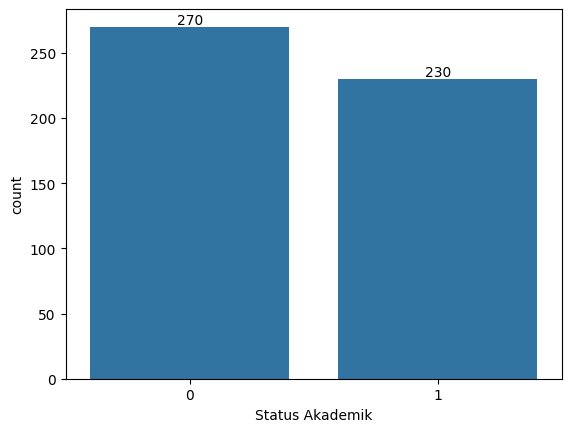

In [ ]:
#visualisasi hasil status akademik
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.countplot(x=df['Status Akademik'])

# tambahkan angka di atas bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')

plt.show()

In [ ]:

# 9. ANALISIS KORELASI

import matplotlib.pyplot as plt
import seaborn as sns

# Memilih fitur numerik dan target
data_korelasi = df[
    [
        'IPK',
        'Nilai Tugas (rata-rata)',
        'Kehadiran (%)',
        'Aktivitas E-Learning (skor)',
        'Partisipasi Diskusi (skor)',
        'Status Akademik'
    ]
]

# Menghitung korelasi
matriks_korelasi = data_korelasi.corr()

# Menampilkan nilai korelasi
print("Matriks Korelasi:")
print(matriks_korelasi)



Matriks Korelasi:
                                  IPK  Nilai Tugas (rata-rata)  Kehadiran (%)  \
IPK                          1.000000                -0.015888       0.059391   
Nilai Tugas (rata-rata)     -0.015888                 1.000000       0.047527   
Kehadiran (%)                0.059391                 0.047527       1.000000   
Aktivitas E-Learning (skor)  0.051865                 0.051517       0.026349   
Partisipasi Diskusi (skor)   0.072762                 0.004090      -0.063529   
Status Akademik             -0.282768                -0.263509      -0.213268   

                             Aktivitas E-Learning (skor)  \
IPK                                             0.051865   
Nilai Tugas (rata-rata)                         0.051517   
Kehadiran (%)                                   0.026349   
Aktivitas E-Learning (skor)                     1.000000   
Partisipasi Diskusi (skor)                     -0.075148   
Status Akademik                                -0.2006

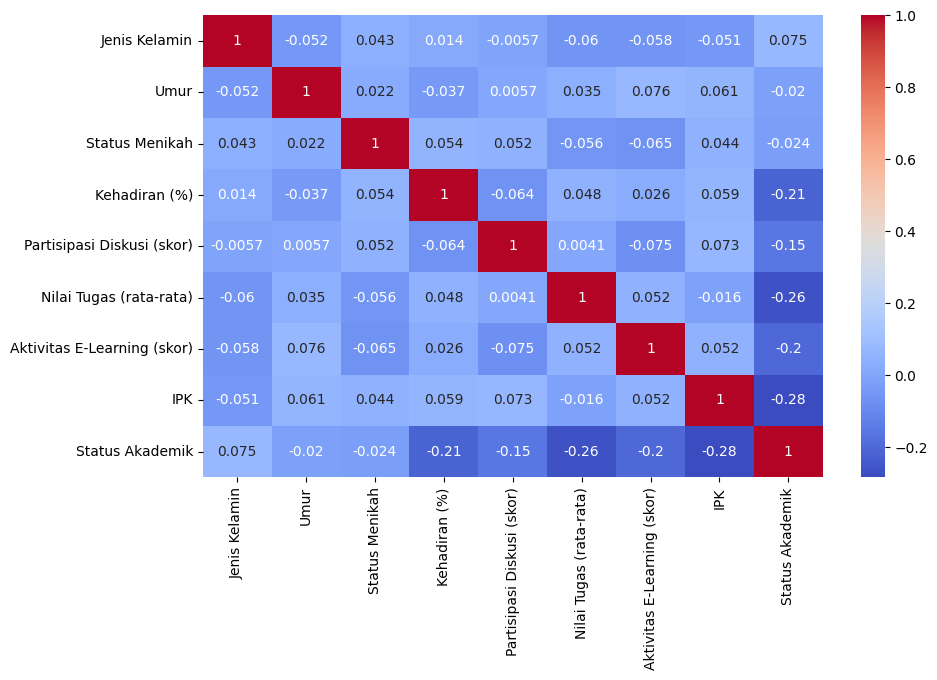

In [ ]:
#Headmap Korelasi Hubungan antar variabel
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

In [ ]:

# 5. PERBANDINGAN PEMBAGIAN DATA TRAINING DAN TESTING

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

# Menyimpan hasil akurasi setiap rasio
hasil_split = []

# Daftar rasio data testing
rasio_testing = [0.2, 0.3, 0.4]

for rasio in rasio_testing:

    # Membagi data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=rasio,
        random_state=42,
        stratify=y
    )

    # Standardisasi khusus Logistic Regression
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Melatih model Logistic Regression
    model_lr = LogisticRegression(max_iter=1000)
    model_lr.fit(X_train_scaled, y_train)

    # Prediksi data testing
    prediksi = model_lr.predict(X_test_scaled)

    # Menghitung akurasi
    akurasi = accuracy_score(y_test, prediksi)

    # Menyimpan hasil
    hasil_split.append({
        'Pembagian Data': f'{int((1-rasio)*100)}:{int(rasio*100)}',
        'Data Training': len(X_train),
        'Data Testing': len(X_test),
        'Accuracy': akurasi
    })

# Membuat tabel hasil
hasil_split = pd.DataFrame(hasil_split)

print("Hasil Perbandingan Pembagian Data:")
display(hasil_split.round(4))


Hasil Perbandingan Pembagian Data:


,Pembagian Data,Data Training,Data Testing,Accuracy
0,80:20,400,100,0.730
1,70:30,350,150,0.740
2,60:40,300,200,0.725


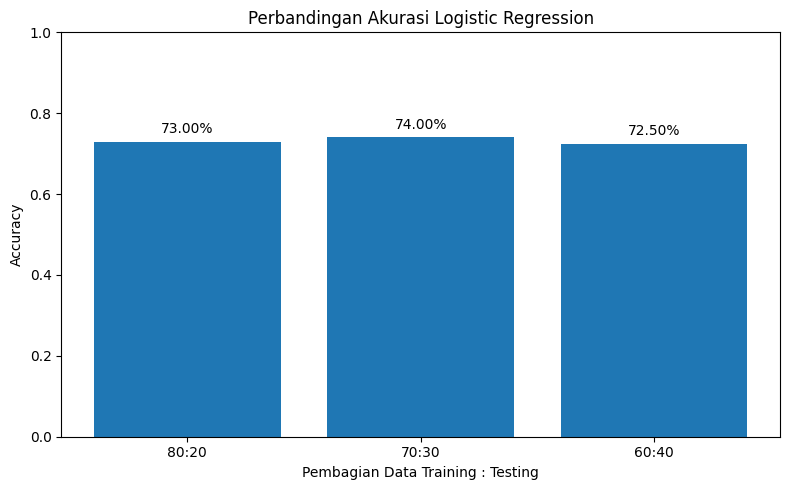

In [ ]:

# 6. VISUALISASI PERBANDINGAN AKURASI

plt.figure(figsize=(8, 5))

bars = plt.bar(
    hasil_split['Pembagian Data'],
    hasil_split['Accuracy']
)

plt.title('Perbandingan Akurasi Logistic Regression')
plt.xlabel('Pembagian Data Training : Testing')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

# Menampilkan nilai akurasi di atas setiap batang
for bar in bars:
    nilai = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        nilai + 0.02,
        f'{nilai:.2%}',
        ha='center'
    )

plt.tight_layout()
plt.show()


In [ ]:

# 7. TRAINING TIGA MODEL DENGAN PEMBAGIAN 70:30

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Membagi data: 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

# Scaling khusus Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)
pred_lr = model_lr.predict(X_test_scaled)

# Model 2: Decision Tree
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train, y_train)
pred_dt = model_dt.predict(X_test)

# Model 3: Random Forest
model_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)
model_rf.fit(X_train, y_train)
pred_rf = model_rf.predict(X_test)

print("\nKetiga model berhasil dilatih dan diuji dengan rasio 70:30.")


Jumlah data training: 350
Jumlah data testing: 150

Ketiga model berhasil dilatih dan diuji dengan rasio 70:30.


Hasil Perbandingan Model:


,Model,Accuracy
0,Random Forest,0.7933
1,Logistic Regression,0.7400
2,Decision Tree,0.7267


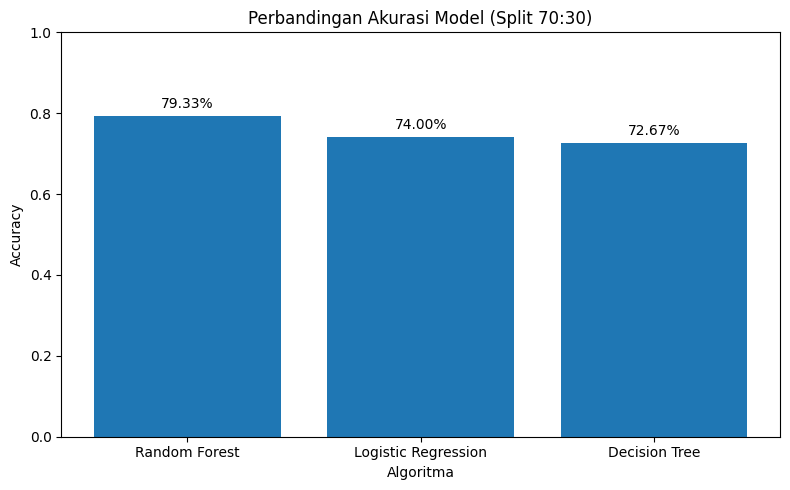

Model dengan akurasi tertinggi: Random Forest
Akurasi tertinggi: 79.33%


In [ ]:

# 8. PERBANDINGAN AKURASI TIGA MODEL

from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

hasil_model = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, pred_lr),
        accuracy_score(y_test, pred_dt),
        accuracy_score(y_test, pred_rf)
    ]
})

hasil_model = hasil_model.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("Hasil Perbandingan Model:")
display(hasil_model.round(4))

# Grafik perbandingan akurasi
plt.figure(figsize=(8, 5))

bars = plt.bar(
    hasil_model['Model'],
    hasil_model['Accuracy']
)

plt.title('Perbandingan Akurasi Model (Split 70:30)')
plt.xlabel('Algoritma')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

for bar in bars:
    nilai = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        nilai + 0.02,
        f'{nilai:.2%}',
        ha='center'
    )

plt.tight_layout()
plt.show()

# Menentukan model dengan akurasi tertinggi
model_terbaik = hasil_model.iloc[0]

print("Model dengan akurasi tertinggi:",
      model_terbaik['Model'])
print("Akurasi tertinggi:",
      f"{model_terbaik['Accuracy']:.2%}")


In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Menghitung Confusion Matrix Random Forest
cm = confusion_matrix(y_test, pred_rf)

# Menampilkan grafik
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_target.classes_
)

display_cm.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Random Forest')
plt.show()

# Menampilkan nilai dalam bentuk angka
print("Confusion Matrix:")
print(cm)


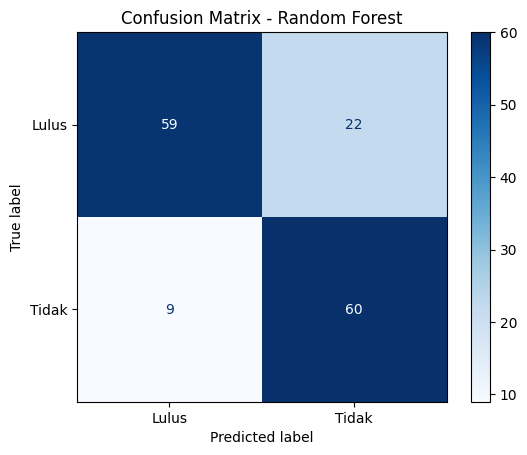

Confusion Matrix Random Forest:
[[59 22]
 [ 9 60]]


In [ ]:

# CONFUSION MATRIX - RANDOM FOREST

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Prediksi data pengujian menggunakan Random Forest
pred_rf = model_rf.predict(X_test)

# Menghitung Confusion Matrix
cm_rf = confusion_matrix(y_test, pred_rf)

# Menampilkan grafik Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=le_target.classes_
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Random Forest')
plt.show()

# Menampilkan nilai Confusion Matrix
print("Confusion Matrix Random Forest:")
print(cm_rf)


Urutan Feature Importance:


,Fitur,Importance
0,IPK,0.2673
1,Nilai Tugas (rata-rata),0.2250
3,Aktivitas E-Learning (skor),0.1808
2,Kehadiran (%),0.1738
4,Partisipasi Diskusi (skor),0.1533


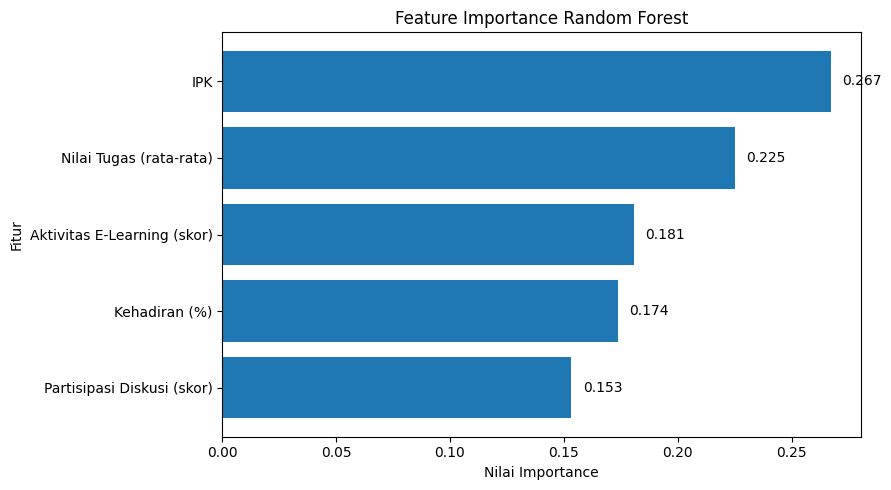

In [ ]:

# 10. FEATURE IMPORTANCE RANDOM FOREST

import pandas as pd
import matplotlib.pyplot as plt

# Mengambil nilai kepentingan setiap fitur
feature_importance = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': model_rf.feature_importances_
})

# Mengurutkan dari nilai tertinggi
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Urutan Feature Importance:")
display(feature_importance.round(4))

# Membuat grafik
plt.figure(figsize=(9, 5))

bars = plt.barh(
    feature_importance['Fitur'],
    feature_importance['Importance']
)

plt.title('Feature Importance Random Forest')
plt.xlabel('Nilai Importance')
plt.ylabel('Fitur')
plt.gca().invert_yaxis()

for bar in bars:
    nilai = bar.get_width()
    plt.text(
        nilai + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f'{nilai:.3f}',
        va='center'
    )

plt.tight_layout()
plt.show()


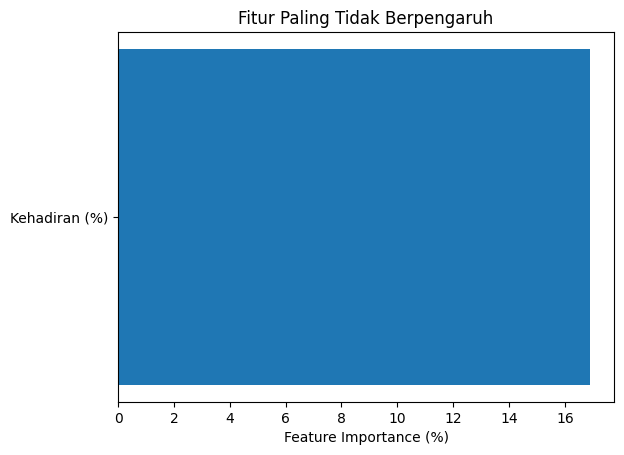

Fitur: Kehadiran (%) (16.92%)


In [ ]:
# Fitur paling tidak berpengaruh
importance = pd.Series(
    model_rf.feature_importances_,
    index=X_train.columns
) * 100

terendah = importance.idxmin()

plt.barh(terendah, importance[terendah])
plt.title("Fitur Paling Tidak Berpengaruh")
plt.xlabel("Feature Importance (%)")
plt.show()

print(f"Fitur: {terendah} ({importance[terendah]:.2f}%)")

In [ ]:
# Fitur paling berpengaruh
importance = pd.Series(model_rf.feature_importances_, index=X_train.columns)

fitur = importance.idxmax()

print("Fitur paling berpengaruh:", fitur)
print("Nilai:", round(importance[fitur] * 100, 2), "%")

Fitur paling berpengaruh: IPK
Nilai: 25.92 %


In [ ]:

# 11. KESIMPULAN HASIL KLASIFIKASI

# Menampilkan model dengan akurasi tertinggi
model_terbaik = hasil_model.iloc[0]

print("=== KESIMPULAN HASIL KLASIFIKASI ===")
print(f"Model terbaik: {model_terbaik['Model']}")
print(f"Akurasi: {model_terbaik['Accuracy']:.2%}")

# Menampilkan fitur dengan importance tertinggi
fitur_tertinggi = feature_importance.iloc[0]

print("\nFitur dengan Importance tertinggi:")
print(fitur_tertinggi['Fitur'])
print(f"Nilai Importance: {fitur_tertinggi['Importance']:.4f}")

print("\nKesimpulan:")
print(
    f"Berdasarkan pengujian, model {model_terbaik['Model']} "
    f"memiliki akurasi tertinggi sebesar "
    f"{model_terbaik['Accuracy']:.2%}. "
    f"Pada model Random Forest, fitur dengan importance "
    f"tertinggi adalah {fitur_tertinggi['Fitur']}."
)


=== KESIMPULAN HASIL KLASIFIKASI ===
Model terbaik: Random Forest
Akurasi: 79.33%

Fitur dengan Importance tertinggi:
IPK
Nilai Importance: 0.2673

Kesimpulan:
Berdasarkan pengujian, model Random Forest memiliki akurasi tertinggi sebesar 79.33%. Pada model Random Forest, fitur dengan importance tertinggi adalah IPK.


In [ ]:

# 12. PREDIKSI DATA MAHASISWA BARU

import pandas as pd

# Memilih model terbaik berdasarkan hasil perbandingan
nama_model = model_terbaik['Model']

if nama_model == 'Logistic Regression':
    model_prediksi = model_lr
elif nama_model == 'Decision Tree':
    model_prediksi = model_dt
else:
    model_prediksi = model_rf

# Input data mahasiswa baru
print("=== INPUT DATA MAHASISWA BARU ===")

ipk = float(input("Masukkan IPK (0-4): "))
nilai_tugas = float(input("Masukkan nilai tugas (0-100): "))
kehadiran = float(input("Masukkan kehadiran (0-100): "))
aktivitas = float(input("Masukkan skor aktivitas E-Learning: "))
diskusi = float(input("Masukkan skor partisipasi diskusi: "))

# Menyusun data sesuai urutan fitur saat pelatihan
data_baru = pd.DataFrame([[
    ipk,
    nilai_tugas,
    kehadiran,
    aktivitas,
    diskusi
]], columns=X.columns)

# Logistic Regression menggunakan data yang sudah distandardisasi
if nama_model == 'Logistic Regression':
    data_baru_proses = scaler.transform(data_baru)
    hasil_prediksi = model_prediksi.predict(data_baru_proses)
else:
    hasil_prediksi = model_prediksi.predict(data_baru)

# Mengubah hasil prediksi ke label semula
status_prediksi = le_target.inverse_transform(
    hasil_prediksi.astype(int)
)[0]

print("\n=== HASIL PREDIKSI ===")
print("Status Akademik:", status_prediksi)


=== INPUT DATA MAHASISWA BARU ===
Masukkan IPK (0-4): 3.5
Masukkan nilai tugas (0-100): 90
Masukkan kehadiran (0-100): 90
Masukkan skor aktivitas E-Learning: 85
Masukkan skor partisipasi diskusi: 90

=== HASIL PREDIKSI ===
Status Akademik: Lulus


In [ ]:
df_head = df.head(10)


In [ ]:
df_head = df.head(10)